# Cadeias de Markov em tempo contínuo

## Importar as bibliotecas

In [1]:
import numpy as np
from IPython.display import Image, display

## Conectar com Google Drive

In [2]:
# Conectar com o Google Drive
# Execução local (fora do Colab): o drive.mount foi substituído por uma pasta local
# from google.colab import drive
# drive.mount('/content/gdrive')

## Variáveis de ambiente para arquivos e conversão para PDF

In [3]:
# Path para pasta de DADOS (local)
caminho_dados = './'

# Path para pasta de PDF
caminho_pdf = './'

# Nome do notebook
nome = 'CMTC'

## Função cmtcPtoQ
Converte a matriz de transição de um passo (P) para a matriz Q

In [4]:
def cmtcPtoQ(P, Mu):
    [r,c] = P.shape
    Q = np.empty_like(P)
    if ((r != c) | np.any(np.sum(P, 1) != 1)):
        raise Exception('Matriz P invalida!')

    for x in range(0, r):
        Q[x, :] = Mu[x] * P[x, :]
        Q[x, x] = -np.sum(Q[x, :])
    return Q

## Exercício 1
Implementar uma função cmtcP para calcular o estado permanente de uma cadeia de Markov em tempo contínuo.<br>
A função recebe como argumento a matriz de probabilidades de um passo (P)<br><br>
Algoritmo:
* Testa se a matriz está corretamente construída<br>
Matriz quadrada e valores de uma linha tem que somar 0
* Calcula matriz A <br>
A = Transposta(Q) <br>
A = A concatenada com vetor de 1s de tamanho n (usar np.vstack para concatenar)
* Calcula vetor B <br>
B = vetor de zeros de tamanho n concatenado com [1]
* Calcular o vetor PI <br>
Usar a função np.linalg.pinv para calcular A_pinv<br>
Usar a função np.dot para multiplicar A_pinv e B

In [5]:
def cmtcP(Q):
    [r,c] = Q.shape
    # A matriz que deve duas minensões iguais
    # A soma das linhas deve ser igual a 0
    # Na construção da matriz podem ser gerados valores cuja soma é muito próxima de zero
    # Testar se o valor da soma é muito próximo de zero
    if ((r != c) | (not np.all(np.isclose(np.sum(Q, 1),0)))):
        raise Exception('Matriz Q invalida!')

    # Coloque seu código aqui
    # A = Transposta(Q) concatenada com uma linha de 1s (condição de normalização)
    A = np.vstack((Q.T, np.ones(r)))
    # B = vetor de zeros de tamanho n concatenado com [1]
    B = np.concatenate((np.zeros(r), [1]))
    # PI = pseudo-inversa(A) . B  (solução de PI.Q = 0 com soma(PI) = 1)
    A_pinv = np.linalg.pinv(A)
    PI = np.dot(A_pinv, B)

    return PI

## Exercício 2
Um dispositivo pode estar em cinco estado: (0) desligado, (1) em aquecimento, (2) em operação, (3) em esfriamento, e (4) em manutenção. O dispositivo passa em média 40 minutos desligado. Sempre que é ligado, o dispositivo vai para aquecimento, onde permanece em média por 20 minutos. Depois do aquecimento o dispositivo vai para operação normal, exceto quando ocorre um problema e precisa ir para manutenção. A probabilidade de o dispositivo em aquecimento precisar de manutenção é 0,08. O dispositivo permanece em operação em média por uma hora, indo para o esfriamento antes de desligar. Também é possível que o dispositivo em funcionamento precise ir para manutenção, o que ocorre com uma probabilidade de 0,12. O dispositivo permanece em média por 10 minutos em resfriamento antes de ser desligado. A probabilidade de o dispositivo em resfriamento precisar de manutenção é 0,04. O tempo médio para dar manutenção ao dispositivo é de 30 minutos. Quando a manutenção termina o dispositivo vai para o estado desligado. Que proporção do tempo o dispositivo permanece em operação?<br>

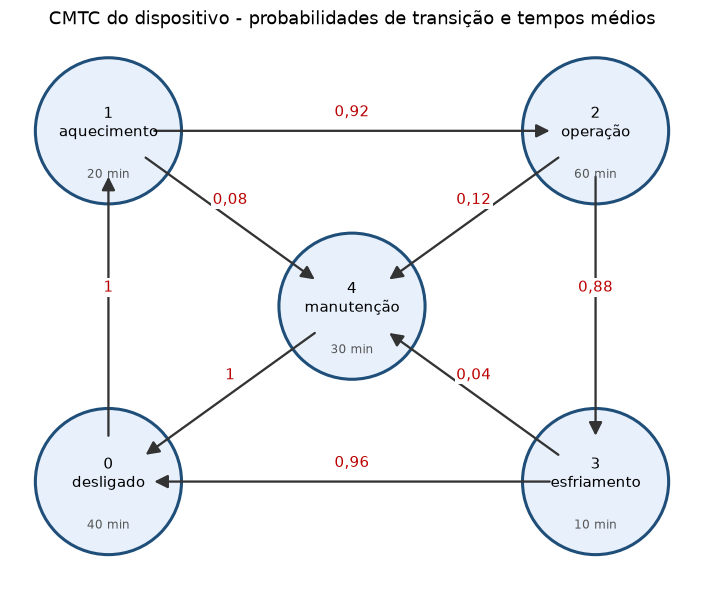

In [6]:
display(Image(caminho_dados + 'markov2.png'))

### Taxas de permanência
* Tempo médio de permanência no estado 0 (desligado) = 40
* $\mu_{0}$ (taxa de permanência no estado 0) = 1/40
* Tempo médio de permanência no estado 1 (em aquecimento) = 20
* $\mu_{1}$ (taxa de permanência no estado 1 = 1/20
* Tempo médio de permanência no estado 2 (em funcionamento) = 60
* $\mu_{2}$ (taxa de permanência no estado 2 = 1/60
* Tempo médio de permanência no estado 3 (em resfriamento) = 10
* $\mu_{3}$ (taxa de permanência no estado 3 = 1/10
* Tempo médio de permanência no estado 4 (em manutenção) = 30
* $\mu_{4}$ (taxa de permanência no estado 4 = 1/30

In [7]:
# Vetor de taxas de permanência
Mu = np.array([1/40, 1/20, 1/60, 1/10, 1/30])
print(Mu)

[0.025      0.05       0.01666667 0.1        0.03333333]


### Probabilidades de transição
* $p_{01}$ (probabilidade de o dispositivo desligado ir para aquecimento) = 1
* $p_{14}$ (probabilidade de o dispositivo em aquecimento precisar de manutenção) = 0,08
* $p_{14} + p_{12}=1$
* $p_{12}$ (probabilidade de o dispositivo em aquecimento não precisar de manutenção) = 1 - 0,08 = 0,92
* $p_{24}$ (probabilidade de o dispositivo em operação precisar de manutenção) = 0,12
* $p_{24} + p_{23}=1$
* $p_{23}$ (probabilidade de o dispositivo em aquecimento não precisar de manutenção) = 1 - 0,12 = 0,88
* $p_{34}$ (probabilidade de o dispositivo em resfriamento precisar de manutenção) = 0,04
* $p_{34} + p_{30}=1$
* $p_{30}$ (probabilidade de o dispositivo em aquecimento não precisar de manutenção) = 1 - 0,04 = 0,96
* $p_{40}$ (probabilidade de o dispositivo em manutenção ir para o estado desligado) = 1

In [8]:
# Criar e imprimir a matriz P
P = np.array([[0,    1,    0,    0,    0   ],
              [0,    0,    0.92, 0,    0.08],
              [0,    0,    0,    0.88, 0.12],
              [0.96, 0,    0,    0,    0.04],
              [1,    0,    0,    0,    0   ]])
print(P)

[[0.   1.   0.   0.   0.  ]
 [0.   0.   0.92 0.   0.08]
 [0.   0.   0.   0.88 0.12]
 [0.96 0.   0.   0.   0.04]
 [1.   0.   0.   0.   0.  ]]


### Taxas de transição
* $\mu_{01}=\mu_{0}\cdot p_{01} = 1/40 \cdot 1 = 0,0250$
* $\mu_{12}=\mu_{1}\cdot p_{12} = 1/20 \cdot 0,92 = 0,0460$
* $\mu_{14}=\mu_{1}\cdot p_{14} = 1/20 \cdot 0,08 = 0,0040$
* $\mu_{23}=\mu_{2}\cdot p_{23} = 1/60 \cdot 0,88 = 0,0147$
* $\mu_{24}=\mu_{2}\cdot p_{24} = 1/60 \cdot 0,12 = 0,0020$
* $\mu_{30}=\mu_{3}\cdot p_{30} = 1/10 \cdot 0,96 = 0,0960$
* $\mu_{34}=\mu_{3}\cdot p_{34} = 1/10 \cdot 0,04 = 0,0040$
* $\mu_{40}=\mu_{4}\cdot p_{40} = 1/30 \cdot 1 = 0,0333$

### Usar a função cmtcPtoQ para calcular a matriz Q

In [9]:
# Calcular a matriz Q
Q = cmtcPtoQ(P, Mu)

# Usar as taxas de transição com 4 casas decimais, como na tabela "Taxas de transição" acima
# (mu01=0,0250  mu12=0,0460  mu14=0,0040  mu23=0,0147  mu24=0,0020  mu30=0,0960  mu34=0,0040  mu40=0,0333)
Q = np.round(Q, 4)
np.fill_diagonal(Q, 0)
np.fill_diagonal(Q, -np.sum(Q, 1))   # diagonal = -(soma das taxas de saída)

np.set_printoptions(precision=4, suppress=True)
print(Q)

[[-0.025   0.025   0.      0.      0.    ]
 [ 0.     -0.05    0.046   0.      0.004 ]
 [ 0.      0.     -0.0167  0.0147  0.002 ]
 [ 0.096   0.      0.     -0.1     0.004 ]
 [ 0.0333  0.      0.      0.     -0.0333]]


### Usar a função cmtcP para calcular o vetor PI

In [10]:
# Calcular o vetor PI
# Se o seu código estiver correto a respota deve ser [0.30799585 0.15399792 0.4241859  0.06235533 0.05146501]
np.set_printoptions(precision=8, suppress=True)
PI = cmtcP(Q)
print(PI)
print('Soma de PI =', PI.sum())
print('Verificação PI.Q = 0:', np.allclose(PI @ Q, 0))

[0.30799585 0.15399792 0.4241859  0.06235533 0.05146501]
Soma de PI = 0.9999999999999992
Verificação PI.Q = 0: True


### Resposta
O dispositivo permanece **em operação (estado 2) cerca de 42,4 % do tempo** ($\pi_2 = 0{,}4242$).

In [11]:
estados = ['desligado', 'aquecimento', 'operação', 'esfriamento', 'manutenção']
for e, p in zip(estados, PI):
    print(f'{e:12s}: {p:.4f}  ({p*100:.2f} % do tempo)')
print(f'\nProporção do tempo em operação = {PI[2]:.4f} ({PI[2]*100:.2f} %)')

desligado   : 0.3080  (30.80 % do tempo)
aquecimento : 0.1540  (15.40 % do tempo)
operação    : 0.4242  (42.42 % do tempo)
esfriamento : 0.0624  (6.24 % do tempo)
manutenção  : 0.0515  (5.15 % do tempo)

Proporção do tempo em operação = 0.4242 (42.42 %)


### Observação
A matriz Q foi montada com as taxas de transição da tabela (4 casas decimais), o que reproduz exatamente a resposta esperada no enunciado.
Usando as taxas sem arredondamento ($\mu_2 = 1/60$, $\mu_4 = 1/30$) obtém-se $\pi_2 = 0{,}4247$, praticamente o mesmo resultado (cerca de 42 % do tempo em operação).